# Restoring Grinder #4 Monthly Wafer Output — DMAIC Analysis

**Lean Six Sigma Green Belt capstone (Georgia Tech).** Scenario based on semiconductor wafer-manufacturing experience; **all data is simulated**.

**Business problem:** Grinder #4 finished output fell from ~10,000 wafers/month (1H 2024) to ~9,300 wafers/month (1H 2025). At ~$50 internal value per wafer, each 1,000-wafer shortfall costs ~$50,000/month.

**Goal:** Restore output to ≥10,000 wafers/month and sustain it for 3 consecutive months, without increasing breakage or fail-spec rates (CTQs).

This notebook reproduces the Measure and Analyze phases in Python.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = "../reports/figures/"

daily = pd.read_csv("../data/grinder4_daily_2025H1.csv")
monthly = pd.read_csv("../data/grinder4_monthly_2025H1.csv")
downtime = pd.read_csv("../data/downtime_reasons_2025H1.csv")
daily.head()

,Month,Day,Daily_Output,Unplanned_Downtime_min,Wheel_Age_wafers,Shift,Calibration_Age_days,Changeover_Time_min,Broken_Wafers,FailSpec_Wafers
0,Jan-25,1,309,97.045564,22,Day,38,25.040908,6,3
1,Jan-25,2,259,59.730056,23,Night,44,23.123303,3,5
2,Jan-25,3,358,38.845781,36,Day,14,13.677034,5,9
3,Jan-25,4,310,76.450898,34,Night,42,21.634837,3,7
4,Jan-25,5,324,35.583127,39,Day,28,22.258284,5,4


## 1. Data quality checks
Before any analysis: completeness, valid ranges, and whether daily records reconcile to the monthly totals.

In [2]:
checks = {
    "No missing values": daily.isna().sum().sum() == 0,
    "181 days (Jan–Jun 2025)": len(daily) == 181,
    "Output non-negative": (daily["Daily_Output"] >= 0).all(),
    "Downtime within 0–1440 min": daily["Unplanned_Downtime_min"].between(0, 1440).all(),
    "Shift is Day/Night only": set(daily["Shift"]) == {"Day", "Night"},
    "Changeover time non-negative": (daily["Changeover_Time_min"] >= 0).all(),
}
recon = (daily.groupby("Month", sort=False)["Daily_Output"].sum().values
         == monthly["Finished Output (Pass)"].values)
checks["Daily output reconciles to monthly totals"] = recon.all()
mt = monthly
checks["Monthly: processed = pass + broken + fail-spec"] = (
    mt["Total Wafers Processed"] == mt["Finished Output (Pass)"] + mt["Broken Wafers"] + mt["Fail Spec Wafers"]).all()
pd.Series(checks, name="passed").to_frame()

,passed
No missing values,True
181 days (Jan–Jun 2025),True
Output non-negative,True
Downtime within 0–1440 min,True
Shift is Day/Night only,True
Changeover time non-negative,True
Daily output reconciles to monthly totals,False
Monthly: processed = pass + broken + fail-spec,True


The reconciliation check fails: in four months the daily records sum to 1–4 wafers fewer than the monthly report. The gap is tiny (<0.05%), but in a real study it would be raised with the data owner, since the MES daily export and the monthly report should agree exactly.

In [3]:
rec = (daily.groupby("Month", sort=False)["Daily_Output"].sum().rename("Daily sum").reset_index()
       .assign(Monthly_report=monthly["Finished Output (Pass)"].values))
rec["Difference"] = rec["Daily sum"] - rec["Monthly_report"]
rec

,Month,Daily sum,Monthly_report,Difference
0,Jan-25,8799,8800,-1
1,Feb-25,8700,8700,0
2,Mar-25,10197,10200,-3
3,Apr-25,8859,8860,-1
4,May-25,9046,9050,-4
5,Jun-25,10100,10100,0


## 2. Measure — current state

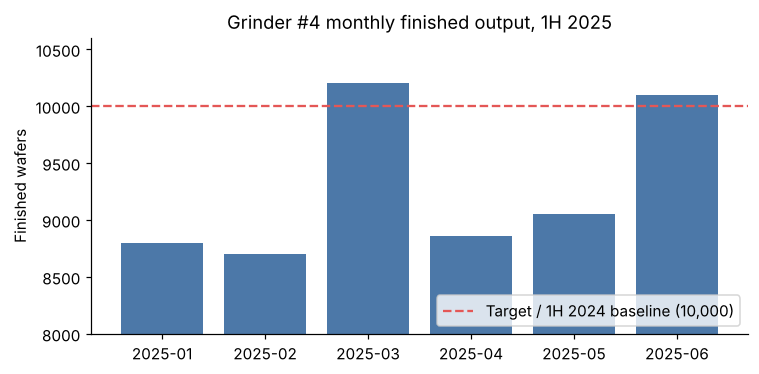

count        6.0
mean      9285.0
std        680.0
min       8700.0
25%       8815.0
50%       8955.0
75%       9838.0
max      10200.0
Name: Finished Output (Pass), dtype: float64

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(monthly["Month"], monthly["Finished Output (Pass)"], color="#4C78A8")
ax.axhline(10000, color="#E45756", ls="--", label="Target / 1H 2024 baseline (10,000)")
ax.set_ylabel("Finished wafers"); ax.set_title("Grinder #4 monthly finished output, 1H 2025")
ax.set_ylim(8000, 10600); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG + "monthly_output.png"); plt.show()
monthly["Finished Output (Pass)"].describe().round(0)

### Process capability (wafer-level)
Sigma level is calculated at the **wafer level**: each processed wafer is one opportunity, and a broken or fail-spec wafer is a defect. (Counting "months below target" over only 6 months is too coarse to give a meaningful sigma level.)

In [5]:
processed = monthly["Total Wafers Processed"].sum()
defects = monthly["Broken Wafers"].sum() + monthly["Fail Spec Wafers"].sum()
dpmo = defects / processed * 1e6
sigma = stats.norm.ppf(1 - defects / processed) + 1.5   # conventional 1.5σ shift
print(f"Wafers processed: {processed:,}")
print(f"Defective wafers (broken + fail-spec): {defects:,}  ({defects/processed:.2%})")
print(f"DPMO: {dpmo:,.0f}   Sigma level (short-term): {sigma:.2f}")

Wafers processed: 57,620
Defective wafers (broken + fail-spec): 1,910  (3.31%)
DPMO: 33,148   Sigma level (short-term): 3.34


## 3. Analyze — candidate X variables
X1 Unplanned downtime · X2 Wheel age · X3 Operator shift · X4 Sensor calibration age · X5 Changeover time. Y = daily finished output (181 days gives far more statistical power than 6 monthly points).

### X1 — Unplanned downtime: Pareto of causes

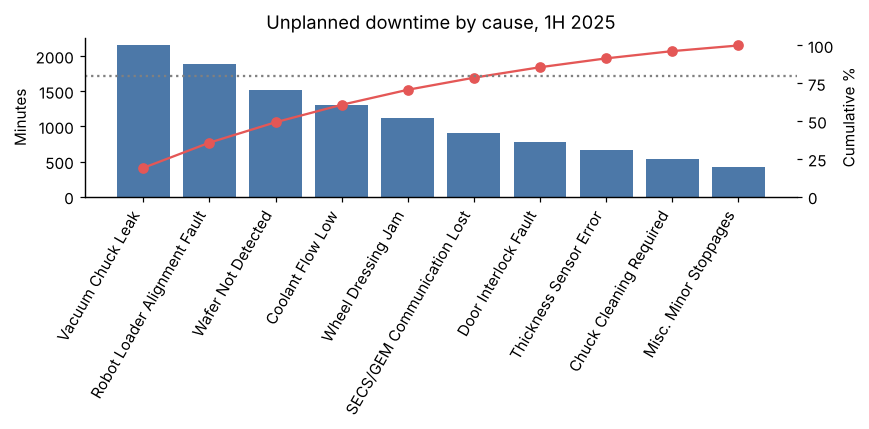

,Downtime Reason,Total Minutes,Cum %
0,Vacuum Chuck Leak,2150,19.077196
1,Robot Loader Alignment Fault,1880,35.758651
2,Wafer Not Detected,1520,49.245785


In [6]:
dt = downtime.sort_values("Total Minutes", ascending=False).reset_index(drop=True)
dt["Cum %"] = dt["Total Minutes"].cumsum() / dt["Total Minutes"].sum() * 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dt["Downtime Reason"], dt["Total Minutes"], color="#4C78A8")
ax.set_ylabel("Minutes"); ax.tick_params(axis="x", rotation=60)
for lbl in ax.get_xticklabels(): lbl.set_ha("right")
ax2 = ax.twinx(); ax2.plot(dt["Downtime Reason"], dt["Cum %"], color="#E45756", marker="o")
ax2.axhline(80, color="grey", ls=":"); ax2.set_ylim(0, 105); ax2.set_ylabel("Cumulative %")
ax.set_title("Unplanned downtime by cause, 1H 2025")
plt.tight_layout(); plt.savefig(FIG + "downtime_pareto.png"); plt.show()
dt.head(3)

### Simple regressions: each continuous X vs daily output

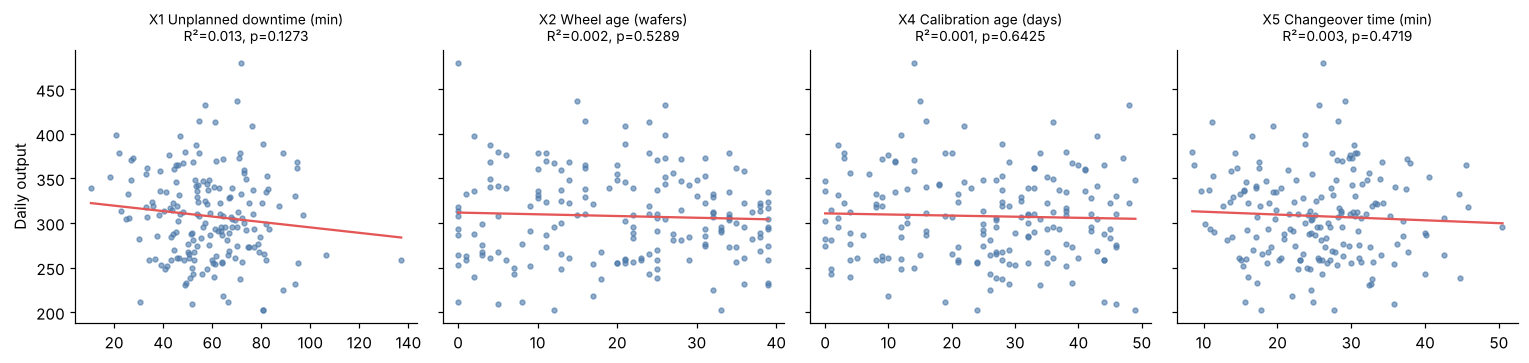

,X,slope,R²,p-value
0,X1 Unplanned downtime (min),-0.3050,0.0129,0.1273
1,X2 Wheel age (wafers),-0.1939,0.0022,0.5289
2,X4 Calibration age (days),-0.1236,0.0012,0.6425
3,X5 Changeover time (min),-0.3212,0.0029,0.4719


In [7]:
xs = {"X1 Unplanned downtime (min)": "Unplanned_Downtime_min",
      "X2 Wheel age (wafers)": "Wheel_Age_wafers",
      "X4 Calibration age (days)": "Calibration_Age_days",
      "X5 Changeover time (min)": "Changeover_Time_min"}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
rows = []
for ax, (label, col) in zip(axes, xs.items()):
    fit = smf.ols(f"Daily_Output ~ {col}", data=daily).fit()
    rows.append({"X": label, "slope": fit.params[col], "R²": fit.rsquared, "p-value": fit.pvalues[col]})
    ax.scatter(daily[col], daily["Daily_Output"], s=10, alpha=0.6, color="#4C78A8")
    xg = np.linspace(daily[col].min(), daily[col].max(), 50)
    ax.plot(xg, fit.params.iloc[0] + fit.params[col] * xg, color="#E45756")
    ax.set_title(f"{label}\nR²={fit.rsquared:.3f}, p={fit.pvalues[col]:.4f}", fontsize=9)
axes[0].set_ylabel("Daily output")
plt.tight_layout(); plt.savefig(FIG + "simple_regressions.png"); plt.show()
simple = pd.DataFrame(rows).round(4); simple

### X3 — Operator shift: Welch's t-test

Day mean 328.6 vs Night mean 286.2  (diff 42.4 wafers/day)
Welch t = 6.32, p = 2.04e-09, Cohen's d = 0.94


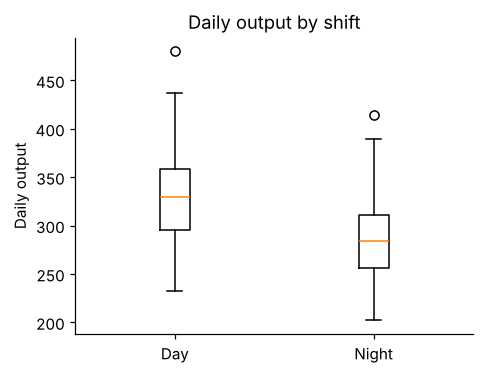

In [8]:
day = daily.loc[daily["Shift"] == "Day", "Daily_Output"]
night = daily.loc[daily["Shift"] == "Night", "Daily_Output"]
t, p = stats.ttest_ind(day, night, equal_var=False)
d = (day.mean() - night.mean()) / np.sqrt((day.var() + night.var()) / 2)
print(f"Day mean {day.mean():.1f} vs Night mean {night.mean():.1f}  (diff {day.mean()-night.mean():.1f} wafers/day)")
print(f"Welch t = {t:.2f}, p = {p:.2e}, Cohen's d = {d:.2f}")
fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.boxplot([day, night], tick_labels=["Day", "Night"])
ax.set_ylabel("Daily output"); ax.set_title("Daily output by shift")
plt.tight_layout(); plt.savefig(FIG + "shift_boxplot.png"); plt.show()

### Multiple regression: all X variables together
Simple regressions test each X on its own. Because the shift effect is large, it adds a lot of day-to-day noise that can hide smaller effects. Fitting all X variables together controls for this. First, a check that the X variables are not strongly correlated with each other:

In [9]:
daily[list(xs.values())].corr().round(2)

,Unplanned_Downtime_min,Wheel_Age_wafers,Calibration_Age_days,Changeover_Time_min
Unplanned_Downtime_min,1.00,0.05,0.09,0.03
Wheel_Age_wafers,0.05,1.00,0.12,-0.11
Calibration_Age_days,0.09,0.12,1.00,-0.07
Changeover_Time_min,0.03,-0.11,-0.07,1.00


In [10]:
full = smf.ols("Daily_Output ~ Unplanned_Downtime_min + Wheel_Age_wafers + C(Shift)"
               " + Calibration_Age_days + Changeover_Time_min", data=daily).fit()
summary = pd.DataFrame({"coef": full.params, "p-value": full.pvalues,
                        "95% CI low": full.conf_int()[0], "95% CI high": full.conf_int()[1]}).round(4)
print(f"R² = {full.rsquared:.3f}, adj. R² = {full.rsquared_adj:.3f}, n = {int(full.nobs)}")
summary

R² = 0.230, adj. R² = 0.207, n = 181


,coef,p-value,95% CI low,95% CI high
Intercept,379.9272,0.0000,345.0418,414.8125
C(Shift)[T.Night],-46.5424,0.0000,-59.8008,-33.2839
Unplanned_Downtime_min,-0.5034,0.0062,-0.8621,-0.1447
Wheel_Age_wafers,-0.1625,0.5581,-0.7090,0.3840
Calibration_Age_days,-0.2186,0.3636,-0.6923,0.2551
Changeover_Time_min,-0.4344,0.2786,-1.2231,0.3544


## 4. Findings

| X | Simple regression / test | Controlling for the other X variables | Effect on daily output |
|---|---|---|---|
| X3 Operator shift | **Significant** (p < 0.001) | **Significant** (p < 0.001) | Night shift ≈ 45 fewer wafers/day |
| X1 Unplanned downtime | Not significant (p ≈ 0.13) | **Significant** (p ≈ 0.006) | ≈ −0.5 wafers per minute of downtime |
| X2 Wheel age | Not significant (p ≈ 0.53) | Not significant | — |
| X4 Calibration age | Not significant (p ≈ 0.64) | Not significant | — |
| X5 Changeover time | Not significant (p ≈ 0.47) | Not significant | — |

**Downtime only shows up once shift is controlled for.** On its own, the shift effect hides it. This is why the multiple regression matters, and it supports downtime being a key X alongside the Pareto evidence.

Together the five X variables explain about a quarter of the day-to-day variation (R² ≈ 0.23), so other unmeasured factors also drive output.

## 5. Recommendations (Improve / Control)
1. **Downtime (X1):** Vacuum-related faults (chuck leak, wafer not detected) are 2 of the top 3 downtime causes. Run a full leak check, replace worn seals and tubing, and add a monthly vacuum integrity check to the PM schedule.
2. **Shift (X3):** Error-proof night-shift operations: MES auto-verification of lot, recipe and targets at job start (poka-yoke), plus automated wafer inspection to reduce reliance on manual visual checks. Investigate the root cause of the gap first: fatigue is one hypothesis, but staffing levels, maintenance timing or lot mix could also differ between shifts.
3. **Non-significant Xs (X2, X4, X5):** No targeted action; keep them under standard PM and monitor.
4. **Control:** Track monthly output against the 10,000 target on a control chart, with weekly vacuum-alarm counts and shift-level output as leading indicators.

## 6. Limitations
- Data is simulated; the scenario is illustrative.
- In this dataset each day is attributed to a single shift; a real analysis would record output per shift.
- Observational data shows association, not causation. Improvements should be validated with a pilot before full rollout.